# Identidades de conciliación, ajustes como líneas y una comparación de regímenes sobre una misma cartera

**Pregunta:** ¿Detecta la conciliación del motor de provisiones los defectos que dice detectar y desde qué tamaño, dejan los ajustes de la administración intacta la PCE del modelo, dónde falla la PCE ponderada en superar a la PCE del escenario promedio, y concilia un banco sintético a través de tres regímenes de provisión?

- **Nivel:** 4, métodos propuestos
- **Requisitos previos:** los notebooks 01 a 07 de este tema
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar la afirmación del SDD en sus cuatro partes y decir qué evidencia tiene cada parte y qué no afirma;
- correr la compuerta de conciliación en seis fechas de reporte, plantar defectos en las tablas, ver qué identidad nombra cada uno y medir el tamaño del menor defecto que la compuerta detecta;
- mostrar que los ajustes son líneas separadas que cambian la reserva total y nada más;
- verificar la desigualdad ponderada sobre promedio como propiedad del régimen convexo con un barrido con semilla, y hallar dónde falla;
- verificar que los tres regímenes de un banco sintético concilian a través de un puente en cada escenario, y decir qué no es esa comparación.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo"}
SCENARIO = {
    "base": "base", "recession": "recesión", "house-price-fall": "precios de viviendas",
    "consumer-arrears-shock": "mora de consumo", "uf-inflation-spike": "inflación UF",
    "combined-severe": "combinado severo",
}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Doce archivos versionados, de dos casos.

- **C06**, las seis fechas de reporte `data/derived/C06/rd-2006-12.json`, `rd-2008-12.json`, `rd-2010-12.json`, `rd-2019-12.json`, `rd-2020-06.json` y `rd-2023-06.json` (préstamos 7(a) de la SBA, Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`): la conciliación del movimiento de la cobertura y del valor contable bruto (`outputs.reconciliation`), el waterfall, los totales por etapa y el bloque de no linealidad.
- **C07**, los seis escenarios `data/derived/C07/base.json`, `recession.json`, `house-price-fall.json`, `consumer-arrears-shock.json`, `uf-inflation-spike.json` y `combined-severe.json`: Banco Andino, un banco **sintético** generado y calibrado a agregados públicos de la CMF. No es un banco real ni evidencia sobre ningún banco. La comparación de los tres regímenes, el puente, los ajustes y las filas de pruebas.

**No se escribió ningún archivo para este notebook**: cada número siguiente se lee de estos archivos o lo calcula el motor sobre ellos, y los defectos plantados se hacen en copias en memoria. La celda siguiente carga los archivos e imprime las versiones del motor que los calculó junto a la versión instalada ahora.

In [2]:
# Cargar las seis fechas de C06 y los seis escenarios de C07 e imprimir las versiones del motor
from scipy.special import ndtri

from riskvalidation.provisions import ecl as ecl_engine, overlays as ovl, reconciliation as rec
from riskvalidation.validation import ifrs9

ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
DATES = ("2006-12", "2008-12", "2010-12", "2019-12", "2020-06", "2023-06")
c06 = {d: json.loads((DERIVED / "C06" / f"rd-{d}.json").read_text(encoding="utf-8")) for d in DATES}
c07 = {n: json.loads((DERIVED / "C07" / f"{n}.json").read_text(encoding="utf-8")) for n in SCENARIO}
baked06 = sorted({a["provenance"]["riskvalidation_version"] for a in c06.values()})
baked07 = sorted({a["provenance"]["riskvalidation_version"] for a in c07.values()})
print("motor que calculó C06:", *baked06, "| motor que calculó C07:", *baked07)
print("motor instalado ahora:", md.version("riskvalidation"))
synthetic = all(a["outputs"]["synthetic"] for a in c07.values())
print("C07 es sintético en cada archivo:", "sí" if synthetic else "no")

motor que calculó C06: 1.0.1 | motor que calculó C07: 1.0.1
motor instalado ahora: 1.0.1
C07 es sintético en cada archivo: sí


## Método

La afirmación del SDD tiene cuatro partes. Cada una es un enunciado que puede fallar, y cada una se prueba abajo sobre archivos versionados con el motor.

1. **La conciliación de IFRS 7 cierra como una compuerta.** Doce identidades atan las tablas por etapa al waterfall, juzgadas por `check_identities` con la base de tolerancia $|\mathrm{diferencia}| \le \mathrm{tolerancia} \times \max(1, G)$, con $G$ la suma de los montos absolutos de cierre de las filas del valor contable bruto (notebook 04). Una compuerta vale por su poder de detección: el notebook planta defectos y mide el tamaño del menor que detecta.
2. **Los ajustes son líneas separadas.** La cobertura total es $\mathrm{CT} = \mathrm{PCE}_{\mathrm{modelo}} + \sum_k \mathrm{AJ}_k$ y los ajustes nunca entran a la PCE del modelo ni a la PCE de etapa (BCBS d350, párrafos 50 y 51; BCE 2024). La prueba es una invariancia: cambiar los ajustes cambia el total y deja intactas las cifras del modelo.
3. **La no linealidad de la PCE ponderada se reproduce.** Con la PD condicional de un factor $PD(z) = \Phi\bigl((\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{\rho}\,z)/\sqrt{1-\rho}\bigr)$ (BCBS 2005; Gordy 2003), que es convexa donde $z \ge \Phi^{-1}(PD^{\mathrm{TTC}})/\sqrt{\rho}$, la desigualdad de Jensen da $\mathbb{E}[PD(Z)] \ge PD(\mathbb{E}[Z])$: la PD ponderada es al menos la PD en el factor medio ponderado **en el régimen convexo**, y puede quedar bajo ella fuera de él. La prueba es un barrido de propiedad con semilla a través de `nonlinearity_test` del motor, más el ejemplo de referencia y las filas versionadas.
4. **Un banco sintético se provisiona bajo tres regímenes con un puente de brecha.** CMF B-1, IFRS 9 como medida de comparación y Anejo 9 del Banco de España (notebook 06). La prueba es una conciliación: los totales son iguales a la suma de sus segmentos y el total B-1 más los pasos del puente es igual al total IFRS 9, en cada escenario.

Lo que la afirmación no es: no es una validación de ningún régimen ni de ningún banco, no declara cumplimiento, y la ausencia de una comparación pública de tres regímenes es lo que encontró la investigación (dossiers 02 y 03), NO VERIFICADO más allá de las búsquedas que esos dossiers registran.

## Comparación

Lo que la práctica y la investigación encontraron antes de este trabajo, con su fuente:

| Práctica | Qué enuncia | Fuente |
|---|---|---|
| Medición de IFRS 9 | objetivo y principios, no fórmulas: la norma «generalmente no prescribe métodos detallados particulares» | GPPC 2016, sección 2.1.1.1; IFRS 9 5.5.17 |
| Conciliación de la cobertura | una revelación por etapa de la cobertura de apertura a la de cierre y del valor contable bruto | IFRS 7 35H y 35I |
| No linealidad | se necesita más de un escenario cuando la pérdida no es lineal en la trayectoria macro; los ajustes solo de PIB la ignoran y subestiman el impacto medio | GPPC 2016, 2.8.1.2; BCE 2024; BCBS d350, párrafo 36(a) |
| Ajustes | deben apoyarse en una metodología, estar atribuidos, asignarse a nivel de parámetro y reflejarse en las etapas; cerca de una cuarta parte de la cobertura de la cartera vigente venía de ajustes en la muestra del BCE | BCE 2024; BCBS d350, párrafos 50 y 51 |
| Chile | los préstamos se provisionan bajo CMF B-1, no bajo el deterioro de IFRS 9 | CNCB A-2 N 5, B-1 |
| España | PCE tipo IFRS 9 con soluciones alternativas supervisoras | Circular 4/2017, Circular 6/2021 |
| Comparación de los regímenes | la investigación persistida (dossiers 02 y 03) **no encontró una comparación pública de los tres sobre una cartera** | las búsquedas de los propios dossiers, NO VERIFICADO más allá de ellas |

La práctica enuncia entonces las identidades como una revelación, los ajustes como un principio y los regímenes como textos separados. No corre las identidades como una compuerta con un umbral de detección medido, no muestra una invariancia de los ajustes y no pone los regímenes sobre una misma cartera.

## Evidencia

Las cuatro partes de la afirmación, cada una con su prueba. Los archivos de evidencia son los de la afirmación (`data/derived/C06/rd-2008-12.json`, `data/derived/C07/base.json`) y las otras fechas y escenarios que la extienden.

### Parte 1: las identidades cierran en seis fechas

Para cada fecha de C06 la celda reconstruye las filas por etapa con el motor, corre `check_identities`, que debe devolver una lista vacía, e imprime el número de identidades, cuántas fallan, el mayor residuo, $G$ y el límite absoluto, con la luz de la prueba propia del motor `reconciliation_identities`. Las tablas de cada fecha se guardan para las partes siguientes.

In [3]:
# Reconstruir las filas por etapa de cada fecha de C06, correr la compuerta de identidades y la prueba propia del motor
tables = {}
for d, art in c06.items():
    recon = art["outputs"]["reconciliation"]
    allow_rows, gca_rows = [], []
    for r in recon["allowance"]:
        moves = {m["line_id"]: m["amount"] for m in r["movements"]}
        allow_rows.append(rec.allowance_rollforward(r["stage"], r["opening"], moves, r["closing"]))
    for r in recon["gross_carrying_amount"]:
        moves = {m["line_id"]: m["amount"] for m in r["movements"]}
        gca_rows.append(rec.gca_rollforward(r["stage"], r["opening"], moves, r["closing"]))
    lines = [dict(line) for line in art["outputs"]["waterfall"]["lines"]]
    stage_ecl = {r["stage"]: r["ecl"] for r in art["outputs"]["stage_summary"]["rows"]}
    tables[d] = (allow_rows, gca_rows, lines, stage_ecl)
    residuals = rec.identity_residuals(allow_rows, gca_rows, lines, stage_ecl)
    failing = rec.check_identities(allow_rows, gca_rows, lines, stage_ecl)
    G = rec.gross_total(gca_rows)
    test = ifrs9.reconciliation_identities(allow_rows, gca_rows, lines, stage_ecl, model_id="L1-dth")
    print(d, "| identidades:", len(residuals), "| fallan:", len(failing), "|", LIGHT[test.light.value])
    print("   mayor residuo, USD:", f"{max(residuals.values()):.1e}", "| G, millones:", round(G / 1e6, 1))
    print("   límite, USD:", round(1e-6 * G, 1))

2006-12 | identidades: 12 | fallan: 0 | verde
   mayor residuo, USD: 1.5e-05 | G, millones: 47124.4
   límite, USD: 47124.4
2008-12 | identidades: 12 | fallan: 0 | verde
   mayor residuo, USD: 1.2e-07 | G, millones: 47247.6
   límite, USD: 47247.6
2010-12 | identidades: 12 | fallan: 0 | verde
   mayor residuo, USD: 3.8e-06 | G, millones: 55459.9
   límite, USD: 55459.9
2019-12 | identidades: 12 | fallan: 0 | verde
   mayor residuo, USD: 1.5e-05 | G, millones: 99603.2
   límite, USD: 99603.2
2020-06 | identidades: 12 | fallan: 0 | verde
   mayor residuo, USD: 1.3e-05 | G, millones: 99710.5
   límite, USD: 99710.5
2023-06 | identidades: 12 | fallan: 0 | verde
   mayor residuo, USD: 1.2e-07 | G, millones: 116761.4
   límite, USD: 116761.4


En cada fecha las doce identidades se cumplen y `check_identities` no devuelve nada. El mayor residuo es a lo más 1,5e-05 USD, el redondeo de los números almacenados, frente a límites de 47.124,4 a 116.761,4 USD que son una millonésima de $G$, que va de 47,1 a 116,8 miles de millones de USD. Los residuos están al menos nueve órdenes de magnitud bajo el límite, así que una compuerta que cierra aquí cierra con un gran margen, y la prueba propia del motor está en verde en las seis fechas. Una compuerta que siempre cierra no probaría nada, y ese es el punto de la parte siguiente.

### Parte 2: una compuerta que detecta defectos plantados

Una compuerta que no puede fallar no prueba nada. La celda planta seis defectos de 1.000.000 USD en copias de las tablas de 2008, uno a la vez, y pregunta qué identidades fallan: un movimiento de la reserva sin su cierre, un movimiento del importe en libros bruto, el cierre de la cascada, una línea de la cascada, la PCE por etapa y un cierre de la reserva. Imprime, para cada uno, si fue detectado y por cuántas identidades.

In [4]:
# Plantar seis defectos de un millón de USD, uno a la vez, en copias de las tablas de 2008
allow, gca, lines, stage_ecl = tables["2008-12"]
recon = c06["2008-12"]["outputs"]["reconciliation"]
D = 1_000_000.0
a1, a2, g2 = recon["allowance"][0], recon["allowance"][1], recon["gross_carrying_amount"][1]
m1 = {m["line_id"]: m["amount"] for m in a1["movements"]}
m2 = {m["line_id"]: m["amount"] for m in a2["movements"]}
mg = {m["line_id"]: m["amount"] for m in g2["movements"]}
up1 = {**m1, "remeasurement": m1["remeasurement"] + D}
bad1 = rec.allowance_rollforward(a1["stage"], a1["opening"], up1, a1["closing"])
bad2 = rec.allowance_rollforward(a2["stage"], a2["opening"], m2, a2["closing"] + D)
upg = {**mg, "repayments": mg["repayments"] + D}
badg = rec.gca_rollforward(g2["stage"], g2["opening"], upg, g2["closing"])
closing_up = [dict(l, amount=l["amount"] + D) if l["id"] == "closing" else dict(l) for l in lines]
remeasure_up = [dict(l, amount=l["amount"] + D) if l["id"] == "remeasurement" else dict(l) for l in lines]
cases = {
    "movimiento de la reserva, Etapa 1, cierre sin cambio": ([bad1] + allow[1:], gca, lines, stage_ecl),
    "movimiento del importe bruto, Etapa 2": (allow, gca[:1] + [badg] + gca[2:], lines, stage_ecl),
    "línea de cierre de la cascada": (allow, gca, closing_up, stage_ecl),
    "línea de nueva medición de la cascada": (allow, gca, remeasure_up, stage_ecl),
    "PCE por etapa, Etapa 1": (allow, gca, lines, {**stage_ecl, "stage1": stage_ecl["stage1"] + D}),
    "cierre de la reserva, Etapa 2": ([allow[0], bad2] + allow[2:], gca, lines, stage_ecl),
}
print("tablas intactas, identidades que fallan:", len(rec.check_identities(allow, gca, lines, stage_ecl)))
for label, args in cases.items():
    failing = rec.check_identities(*args)
    print(f"{label:52s} detectado:", "sí" if failing else "no")
    print(f"{'':52s} identidades que lo nombran:", len(failing))

tablas intactas, identidades que fallan: 0
movimiento de la reserva, Etapa 1, cierre sin cambio detectado: sí
                                                     identidades que lo nombran: 2
movimiento del importe bruto, Etapa 2                detectado: sí
                                                     identidades que lo nombran: 1
línea de cierre de la cascada                        detectado: sí
                                                     identidades que lo nombran: 2
línea de nueva medición de la cascada                detectado: sí
                                                     identidades que lo nombran: 2
PCE por etapa, Etapa 1                               detectado: sí
                                                     identidades que lo nombran: 1
cierre de la reserva, Etapa 2                        detectado: sí
                                                     identidades que lo nombran: 3


Las tablas intactas no fallan en nada, y cada uno de los seis defectos de un millón de USD es detectado. Las identidades que los nombran son las que llevan la cantidad: un movimiento de la reserva sin su cierre lo nombran dos identidades, la fila de la etapa y la línea de la cascada que debe igualar la suma de los movimientos por etapa; un movimiento del importe bruto, su fila de etapa; el cierre de la cascada, dos; una línea de la cascada, dos; la PCE por etapa, la identidad que ata el cierre de la etapa a la PCE; y un cierre de la reserva, tres. Un defecto nunca es silencioso y lo nombra al menos una identidad que dice dónde está.

### Parte 2b: el umbral de detección medido

La compuerta debería detectar un defecto exactamente cuando excede el límite de tolerancia $10^{-6} \times G$. La celda lo prueba en cada una de las seis fechas: planta un defecto de un tamaño dado en la fila de reserva de la Etapa 1, pregunta a `check_identities` si se detecta, y biseca el tamaño entre 0 y 100 millones de USD en 60 pasos para hallar dónde cambia la respuesta. La figura grafica el umbral bisecado contra el límite de cada fecha.

2006-12 | menor defecto detectado, USD: 47124.4 | límite, USD: 47124.4
2008-12 | menor defecto detectado, USD: 47247.6 | límite, USD: 47247.6
2010-12 | menor defecto detectado, USD: 55459.9 | límite, USD: 55459.9
2019-12 | menor defecto detectado, USD: 99603.2 | límite, USD: 99603.2
2020-06 | menor defecto detectado, USD: 99710.5 | límite, USD: 99710.5
2023-06 | menor defecto detectado, USD: 116761.4 | límite, USD: 116761.4


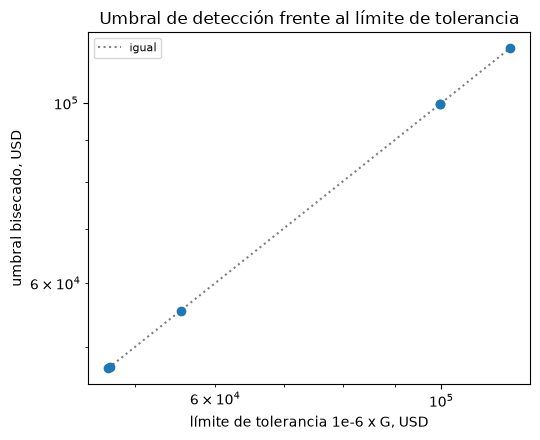

In [5]:
# Bisecar el tamaño de un defecto para hallar desde dónde lo nombra la compuerta, en cada una de las seis fechas
thresholds = {}
for d, (allow, gca, lines, stage_ecl) in tables.items():
    r0 = c06[d]["outputs"]["reconciliation"]["allowance"][0]
    moves = {m["line_id"]: m["amount"] for m in r0["movements"]}
    low, high = 0.0, 1e8
    for _ in range(60):
        middle = 0.5 * (low + high)
        broken = {**moves, "remeasurement": moves["remeasurement"] + middle}
        row = rec.allowance_rollforward(r0["stage"], r0["opening"], broken, r0["closing"])
        if rec.check_identities([row] + allow[1:], gca, lines, stage_ecl):
            high = middle
        else:
            low = middle
    thresholds[d] = (high, 1e-6 * rec.gross_total(gca))
    print(d, "| menor defecto detectado, USD:", round(high, 1), "| límite, USD:", round(thresholds[d][1], 1))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
limits = [v[1] for v in thresholds.values()]
found = [v[0] for v in thresholds.values()]
ax.scatter(limits, found, color="tab:blue", zorder=3)
ax.plot([min(limits), max(limits)], [min(limits), max(limits)], color="grey", linestyle=":", label="igual")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("límite de tolerancia 1e-6 x G, USD")
ax.set_ylabel("umbral bisecado, USD")
ax.set_title("Umbral de detección frente al límite de tolerancia")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

En las seis fechas el umbral bisecado queda sobre la diagonal: un defecto se detecta exactamente desde el tamaño de su límite, $10^{-6} \times G$, que va de 47.124,4 a 116.761,4 USD con el tamaño de la cartera. La compuerta no es ciega bajo su límite ni demasiado sensible sobre él, de modo que su potencia es una función conocida de la cartera, y un validador que la informe en verde debe decir que protege contra un error de decenas de miles de USD y no contra un redondeo de unos miles. Endurecer la tolerancia mueve el umbral en proporción.

### Parte 3: los ajustes son líneas, y solo se mueve el total

La celda reconstruye los dos ajustes de Banco Andino como en el notebook 04 y los pasa a `portfolio_allowance` del motor con una cuenta construida por etapa que representa la PCE por etapa versionada, de modo que las cifras del modelo son las del archivo. Multiplica los ajustes por 0, 1, 10 y 100 y verifica la invariancia: la PCE del modelo y la PCE por etapa nunca cambian, y la reserva total cambia exactamente en el total de ajustes.

In [6]:
# Escalar los ajustes de Banco Andino y verificar que solo se mueven el total de ajustes y la reserva total
detail = c07["base"]["outputs"]["ifrs9_detail"]
row = [t for t in c07["base"]["tests"] if t["test_id"] == "ifrs9.overlay_diagnostics"][0]
split = {amount: target for target, amount in row["extras"]["by_target"].items() if amount}
overlays = [
    ovl.Overlay(id=o["id"], rationale_en=o["label"]["en"], rationale_es=o["label"]["es"], method="expert",
                target=split[o["amount"]], segment_id=o["segment_id"], stage=o["stage"], amount=o["amount"],
                staging_effect="none", review_date="2026-08-31", currency="CLP")  # review date: a lesson input
    for o in detail["overlays"]
]
by_stage = {r["stage"]: r["ecl"] for r in detail["stage_summary"] if r["stage"] != "poci"}
codes = np.array([1, 2, 3])
ecl12, ecl_life, ecl_s3 = (np.array(v) for v in ([by_stage["stage1"], 0.0, 0.0], [0.0, by_stage["stage2"], 0.0],
                                                   [0.0, 0.0, by_stage["stage3"]]))
baseline = ecl_engine.portfolio_allowance(codes, ecl12, ecl_life, ecl_s3, overlays=overlays)
for factor in (0, 1, 10, 100):
    scaled = [dataclasses.replace(o, amount=o.amount * factor) for o in overlays]
    run = ecl_engine.portfolio_allowance(codes, ecl12, ecl_life, ecl_s3, overlays=scaled)
    same = run.model_total == baseline.model_total and run.by_stage == baseline.by_stage
    exact = abs(run.total - (run.model_total + run.overlay_total)) < 1e-6
    print("ajustes x", factor, "| cifras del modelo sin cambio:", "sí" if same else "no")
    print("   total de ajustes, CLP millones:", round(run.overlay_total / 1e6, 1))
    print("   el total se mueve exactamente por los ajustes:", "sí" if exact else "no")
print("reserva total, CLP millones:", round(baseline.total / 1e6, 1))

ajustes x 0 | cifras del modelo sin cambio: sí
   total de ajustes, CLP millones: 0.0
   el total se mueve exactamente por los ajustes: sí
ajustes x 1 | cifras del modelo sin cambio: sí
   total de ajustes, CLP millones: 324.1
   el total se mueve exactamente por los ajustes: sí
ajustes x 10 | cifras del modelo sin cambio: sí
   total de ajustes, CLP millones: 3241.3
   el total se mueve exactamente por los ajustes: sí
ajustes x 100 | cifras del modelo sin cambio: sí
   total de ajustes, CLP millones: 32413.0
   el total se mueve exactamente por los ajustes: sí
reserva total, CLP millones: 97592.0


Con los ajustes multiplicados por 0, 1, 10 y 100 el total del modelo y la PCE por etapa quedan iguales en cada corrida, y la reserva total se mueve exactamente en el total de ajustes: 0, 324,1, 3.241,3 y 32.413 millones de CLP. A los montos versionados la reserva total es 97.592,0 millones de CLP. Los ajustes se mantienen como dos líneas y nunca se funden con la PCE del modelo, que es la afirmación: un ajuste es una línea atribuida que cambia el total y nada más, de modo que un validador puede sumarlo, quitarlo o escalarlo sin tocar el modelo sobre el que se apoya.

### Parte 3b: un ajuste está atado a su etapa

Las identidades hacen más que sumar. El cierre de la reserva de una etapa debe igualar su PCE por etapa más el ajuste llevado en esa etapa. La celda toma las tablas de 2008 de C06, que no tienen ajuste, e inventa uno de 10 millones de USD para la lección. Primero deja el cierre como estaba y pregunta a `check_identities`; luego lleva el ajuste en el cierre de la Etapa 1 y como línea de la cascada y pregunta de nuevo.

In [7]:
# Llevar un ajuste de 10 millones en el cierre de la Etapa 1 y preguntar qué identidades lo notan
allow, gca, lines, stage_ecl = tables["2008-12"]
r1 = c06["2008-12"]["outputs"]["reconciliation"]["allowance"][0]
moves = {m["line_id"]: m["amount"] for m in r1["movements"]}
LESSON = ovl.Overlay(id="LESSON", rationale_en="lesson", rationale_es="lección", method="expert", target="pd",
                     segment_id=None, stage=None, amount=10_000_000.0, staging_effect="none",
                     review_date="2026-08-31", currency="USD")
not_carried = rec.check_identities(allow, gca, lines, stage_ecl, overlays=[LESSON])
carried_row = rec.allowance_rollforward("stage1", r1["opening"], {**moves, "overlay-LESSON": LESSON.amount},
                                        r1["closing"] + LESSON.amount)
raised = [dict(l, amount=l["amount"] + LESSON.amount) if l["id"] == "closing" else dict(l) for l in lines]
overlay_line = {"id": "overlay-LESSON", "kind": "overlay", "overlay_id": "LESSON",
                "amount": LESSON.amount, "stage": None}
all_lines = raised + [overlay_line]
carried = rec.check_identities([carried_row] + allow[1:], gca, all_lines, stage_ecl, overlays=[LESSON])
print("ajuste no llevado en el cierre, identidades que fallan:", len(not_carried))
print("ajuste llevado en el cierre y como línea de la cascada, identidades que fallan:", len(carried))

ajuste no llevado en el cierre, identidades que fallan: 1
ajuste llevado en el cierre y como línea de la cascada, identidades que fallan: 0


Un ajuste de 10 millones de USD que no se lleva en el cierre de la Etapa 1 hace fallar la identidad que ata el cierre a la PCE por etapa y al ajuste. Llevarlo en el cierre y como línea de la cascada vuelve a cerrar todas las identidades. Las tablas son entonces consistentes con el ajuste solo cuando el ajuste está donde dicen las identidades: la compuerta ata un ajuste a su etapa, y un ajuste registrado en el total sin un lugar en la conciliación se detecta como una ruptura y no se acepta como un cuadre.

### Parte 4: la no linealidad, reproducida y acotada

Tres pruebas, en dos celdas. Primero, el ejemplo de referencia del notebook 03 ($PD^{\mathrm{TTC}} = 2\%$, $\rho = 0{,}12$, $z = (+1, 0, -2)$, ponderaciones $(0{,}25, 0{,}5, 0{,}25)$) por `nonlinearity_test`. Segundo, el índice a nivel de PD de los seis segmentos de C07 recalculado desde su PD ponderada y su PD en el factor medio, y el índice a nivel de PCE de las seis fechas de C06 recalculado desde la PCE ponderada y la PCE en la trayectoria media.

In [8]:
# Correr el ejemplo de referencia y recalcular los índices de los segmentos y fechas versionados
ex_z, ex_w = np.array([1.0, 0.0, -2.0]), np.array([0.25, 0.5, 0.25])
example = ifrs9.nonlinearity_test(0.02, 0.12, ex_z, ex_w, model_id="lesson")
print("ejemplo de referencia: PD ponderada y PD en el factor medio, porcentaje:")
print(round(100 * example.extras["pd_weighted"], 3), round(100 * example.extras["pd_at_mean_z"], 3))
print("índice:", round(example.metric, 4), "|", LIGHT[example.light.value])
segments = [t for t in c07["base"]["tests"] if t["test_id"] == "ifrs9.nonlinearity"]
pd_indexes = [ecl_engine.non_linearity_index(t["extras"]["pd_weighted"], t["extras"]["pd_at_mean_z"])
              for t in segments]
print("segmentos de C07: índice a nivel de PD, menor y mayor:")
print(round(min(pd_indexes), 3), round(max(pd_indexes), 3))
for d, art in c06.items():
    block = art["outputs"]["non_linearity"]
    index = ecl_engine.non_linearity_index(block["ecl_weighted"], block["ecl_at_mean_path"])
    print(d, "| índice a nivel de PCE:", round(index, 5))

ejemplo de referencia: PD ponderada y PD en el factor medio, porcentaje:
2.681 1.8
índice: 0.4898 | verde
segmentos de C07: índice a nivel de PD, menor y mayor:
0.156 0.956
2006-12 | índice a nivel de PCE: 0.00211
2008-12 | índice a nivel de PCE: 0.02121
2010-12 | índice a nivel de PCE: -0.00071
2019-12 | índice a nivel de PCE: 0.0232
2020-06 | índice a nivel de PCE: 0.01279
2023-06 | índice a nivel de PCE: 0.00622


El ejemplo de referencia se reproduce: la PD ponderada es 2,681% y la PD en el factor medio 1,800%, un índice de 0,4898. En los seis segmentos de C07 el índice a nivel de PD va de 0,156 a 0,956. A nivel de PCE las seis fechas de C06 dan 0,00211, 0,02121, -0,00071, 0,0232, 0,01279 y 0,00622: cinco están en cero o sobre él, y 2010-12 está bajo, lo que el motor lee como ámbar. La afirmación de que la PCE ponderada excede a la PCE del escenario promedio no se cumple entonces en cada fecha versionada, y el barrido siguiente dice dónde debería cumplirse.

### Parte 4b: el barrido

La celda sortea 4.000 casos con una semilla fija: una PD entre 0,1% y 20% (log-uniforme), una correlación entre 0,01 y 0,30, de dos a cinco escenarios con factores alrededor de un centro aleatorio entre -5 y +1, y ponderaciones de una distribución de Dirichlet. Cada uno pasa por `nonlinearity_test`. Cuenta los sorteos cuyos factores están todos en la región convexa $z \ge \Phi^{-1}(PD^{\mathrm{TTC}})/\sqrt{\rho}$, donde la desigualdad de Jensen prohíbe un índice negativo, los índices negativos de cada grupo y las luces rojas, y termina con un ejemplo cóncavo explícito.

In [9]:
# Sortear 4000 casos con semilla por la prueba del motor y separarlos por la región convexa
rng = np.random.default_rng(20261021)
draws = []
for _ in range(4000):
    pd_ttc = float(np.exp(rng.uniform(np.log(0.001), np.log(0.2))))
    rho = float(rng.uniform(0.01, 0.30))
    k = int(rng.integers(2, 6))
    z = rng.normal(rng.uniform(-5.0, 1.0), rng.uniform(0.3, 1.5), k)
    w = rng.dirichlet(np.ones(k))
    result = ifrs9.nonlinearity_test(pd_ttc, rho, z, w)
    convex = bool(np.all(z >= ndtri(pd_ttc) / math.sqrt(rho)))
    error = result.extras["gauss_hermite_error"]
    draws.append((convex, result.metric, float(np.sum(w * z)), result.light.value, error))
convex_draws = [d for d in draws if d[0]]
other_draws = [d for d in draws if not d[0]]
print("sorteos:", len(draws), "| otros:", len(other_draws))
print("todos los factores en la región convexa:", len(convex_draws))
print("región convexa: menor índice, índices negativos:", round(min(d[1] for d in convex_draws), 6),
      sum(d[1] < 0 for d in convex_draws))
print("fuera de ella: menor índice, índices negativos, luces rojas:", round(min(d[1] for d in other_draws), 4),
      sum(d[1] < 0 for d in other_draws), sum(d[3] == "red" for d in other_draws))
small = all(d[4] <= 1e-9 for d in draws)
print("error de Gauss-Hermite de a lo más 1e-9 en cada sorteo:", "sí" if small else "no")
concave = ifrs9.nonlinearity_test(0.2, 0.3, np.array([-3.0, -4.0]), np.array([0.5, 0.5]), model_id="lesson")
print("un ejemplo cóncavo: índice y luz:", round(concave.metric, 5), LIGHT[concave.light.value])
print("convexa desde z:", round(float(ndtri(0.2) / math.sqrt(0.3)), 3))

sorteos: 4000 | otros: 598
todos los factores en la región convexa: 3402
región convexa: menor índice, índices negativos: 0.0 0
fuera de ella: menor índice, índices negativos, luces rojas: -0.12 356 356
error de Gauss-Hermite de a lo más 1e-9 en cada sorteo: sí
un ejemplo cóncavo: índice y luz: -0.01319 rojo
convexa desde z: -1.537


De los 4.000 sorteos, 3.402 tienen todos los factores de escenario en la región convexa, y ahí el menor índice es 0,0 y ninguno es negativo, como exige la desigualdad de Jensen. De los 598 sorteos con un factor fuera de ella, 356 tienen un índice negativo, hasta -0,12, y todos son rojos. El ejemplo cóncavo, una PD de 0,2 y una correlación de 0,3 con factores -3 y -4, da -0,01319, rojo, y la región convexa parte en z = -1,537. El error de Gauss-Hermite es de a lo más 1e-9 en cada sorteo. La afirmación se cumple entonces con su condición: la PD ponderada es al menos la PD en el factor medio en el régimen convexo y puede estar bajo ella fuera de él.

La figura dibuja el índice de cada sorteo contra su factor medio ponderado, con los sorteos de la región convexa en azul y los demás en rojo.

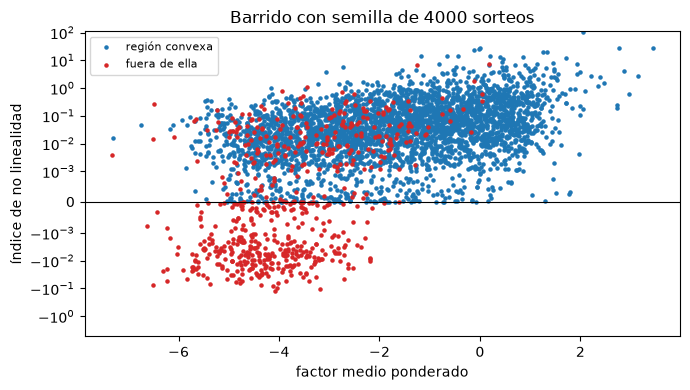

In [10]:
# Dibujar el índice de no linealidad del barrido según el factor medio ponderado
fig, ax = plt.subplots(figsize=(7, 4))
for group, color, label in ((convex_draws, "tab:blue", "región convexa"), (other_draws, "tab:red", "fuera de ella")):
    ax.scatter([d[2] for d in group], [d[1] for d in group], s=5, color=color, label=label)
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set_yscale("symlog", linthresh=1e-3)
ax.set_xlabel("factor medio ponderado")
ax.set_ylabel("índice de no linealidad")
ax.set_title("Barrido con semilla de 4000 sorteos")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los puntos azules nunca caen bajo la línea del cero: en la región convexa el índice es no negativo cualesquiera sean la PD, la correlación y las ponderaciones, porque la PD condicional se curva hacia arriba allí. Los puntos rojos se reparten a ambos lados, y los que quedan bajo la línea son los sorteos cuyos escenarios están en la cola cóncava de la curva, donde la PD se aplana y un promedio de escenarios puede exceder a uno ponderado. La frontera entre las dos nubes es la propiedad que un validador necesita conocer: la condición de la afirmación no es una cautela sino la región donde la identidad es un teorema.

### Parte 5: tres regímenes, un banco sintético, un puente en cada escenario

La última prueba es la conciliación sobre los seis escenarios de Banco Andino. Para cada archivo la celda verifica que el total de cada régimen iguala la suma de sus segmentos más las líneas no asignadas, que el total comparable B-1 más las provisiones adicionales iguala el total B-1 contabilizado, que el total B-1 más los pasos del puente iguala el total IFRS 9, y que el archivo lleva el aviso de sintético en ambos idiomas. Imprime las tres provisiones y la razón de IFRS 9 sobre B-1, una afirmación sobre la misma cartera bajo reglas distintas y no sobre cuál regla es la correcta.

In [11]:
# Conciliar los totales, el total B-1 contabilizado y el puente en cada uno de los seis escenarios
KEYS = ("cmf_b1_provision", "ifrs9_provision", "bde_annex9_provision")
checks = {"sumas": [], "contabilizado": [], "puente": [], "aviso": []}
for name, art in c07.items():
    out = art["outputs"]
    comparison = out["comparison"]
    totals = {k: sum(r[k] for r in comparison["rows"]) + comparison["unallocated"][k] for k in KEYS}
    regimes = {r["regime"]: r["total_provision"] for r in out["regimes"]}
    sums_ok = all(abs(totals[k] - regimes[r]) < 1.0 for k, r in zip(KEYS, ("cmf-b1", "ifrs9", "bde-annex9")))
    extra = out["b1_detail"]["additional_provisions"]["amount"]
    checks["sumas"].append(sums_ok)
    checks["contabilizado"].append(abs(out["b1_detail"]["booked_total"] - (regimes["cmf-b1"] + extra)) < 1.0)
    bridge_end = totals[KEYS[0]] + sum(s["amount"] for s in out["gap_bridge"]["steps"])
    checks["puente"].append(abs(bridge_end - totals[KEYS[1]]) < 1.0)
    checks["aviso"].append(bool(out["notice"]["en"]) and bool(out["notice"]["es"]) and out["synthetic"])
    print(f"{SCENARIO[name]:20s} B-1 {regimes['cmf-b1'] / 1e9:7.1f} | IFRS 9 {regimes['ifrs9'] / 1e9:7.1f}")
    residual = abs(bridge_end - totals[KEYS[1]])
    print(f"{'':20s} IFRS 9 sobre B-1: {regimes['ifrs9'] / regimes['cmf-b1']:6.3f}")
    print(f"{'':20s} residuo del puente, CLP: {residual:.2f}")
print("verificaciones que se cumplen en los seis escenarios:", len(c07), "escenarios")
for key, values in checks.items():
    print("  ", key, "sí" if all(values) else "no")

base                 B-1   152.0 | IFRS 9    97.6
                     IFRS 9 sobre B-1:  0.642
                     residuo del puente, CLP: 0.00
recesión             B-1   197.5 | IFRS 9   169.8
                     IFRS 9 sobre B-1:  0.860
                     residuo del puente, CLP: 0.00
precios de viviendas B-1   168.9 | IFRS 9   128.8
                     IFRS 9 sobre B-1:  0.763
                     residuo del puente, CLP: 0.00
mora de consumo      B-1   178.6 | IFRS 9   126.3
                     IFRS 9 sobre B-1:  0.707
                     residuo del puente, CLP: 0.00
inflación UF         B-1   166.9 | IFRS 9   117.4
                     IFRS 9 sobre B-1:  0.703
                     residuo del puente, CLP: 0.00
combinado severo     B-1   275.8 | IFRS 9   327.8
                     IFRS 9 sobre B-1:  1.189
                     residuo del puente, CLP: 0.00
verificaciones que se cumplen en los seis escenarios: 6 escenarios
   sumas sí
   contabilizado sí
   puente sí
   avi

En los seis escenarios los totales igualan la suma de sus segmentos más las líneas no asignadas, el total B-1 contabilizado iguala el total comparable más las provisiones adicionales, el puente de B-1 a IFRS 9 cierra con un residuo de 0,00 CLP, y cada archivo lleva el aviso de sintético en ambos idiomas. IFRS 9 sobre B-1 va de 0,642 en el escenario base a 1,189 en el caso combinado severo. Es una afirmación de conciliación y del orden de los regímenes sobre una cartera sintética. No es una validación de ningún régimen, y no dice nada sobre si un banco real se provisionaría así.

## Resultados

**Respuesta:** Sí en los cuatro puntos: la compuerta de conciliación cierra sus 12 identidades en seis fechas, detecta cada uno de seis defectos plantados de un millón de USD, y empieza a nombrar un defecto exactamente en su límite de una millonésima del importe en libros bruto (47.247,6 USD en 2008-12 y 116.761,4 en 2023-06); los ajustes cambian solo la reserva total (totales de ajustes de 0,0, 324,1, 3.241,3 y 32.413,0 millones de CLP) mientras las cifras del modelo quedan iguales; el índice ponderado nunca es negativo en la región convexa (3402 sorteos, ninguno negativo) y es negativo en 356 de los 598 sorteos fuera de ella; y los tres regímenes de Banco Andino concilian en los seis escenarios con un residuo del puente de 0,00 CLP, con IFRS 9 sobre B-1 de 0,642 a 1,189.

- **Las identidades cierran en seis fechas.** En cada fecha de C06 las doce identidades se cumplen y `check_identities` devuelve una lista vacía. El mayor residuo es 1,5e-05 USD (2006-12 y 2019-12), 1,3e-05 (2020-06), 3,8e-06 (2010-12) y 1,2e-07 (2008-12 y 2023-06), frente a límites absolutos de 47.124,4, 47.247,6, 55.459,9, 99.603,2, 99.710,5 y 116.761,4 USD, una millonésima de $G$. La prueba propia del motor está en verde en las seis fechas, y los residuos son el redondeo de los números almacenados, al menos nueve órdenes de magnitud bajo el límite.
- **La compuerta detecta lo que debe, y su umbral es la tolerancia.** Seis defectos de 1.000.000 USD se detectan, cada uno por una a tres identidades que llevan la cantidad defectuosa. La bisección halla en cada fecha que un defecto se detecta exactamente desde el tamaño del límite $10^{-6} \times G$: 47.124,4, 47.247,6, 55.459,9, 99.603,2, 99.710,5 y 116.761,4 USD.
- **Los ajustes cambian el total y nada más.** Con los ajustes multiplicados por 0, 1, 10 y 100 las cifras del modelo quedan iguales, y la reserva total se mueve exactamente en el total de ajustes. A los montos versionados es 97.592,0 millones de CLP. Un ajuste de 10 millones de USD que no se lleva en el cierre de la Etapa 1 hace fallar una identidad, y llevarlo en el cierre y como línea de la cascada cierra todas las identidades: las identidades atan el ajuste a su etapa.
- **El ejemplo de no linealidad se reproduce.** La PD ponderada es 2,681% y la PD en el factor medio 1,800%, un índice de 0,4898. En los segmentos versionados de C07 el índice a nivel de PD va de 0,156 a 0,956.
- **La PCE ponderada no siempre está sobre la PCE de la trayectoria media, y la afirmación dice dónde se cumple.** En las fechas versionadas de C06 el índice a nivel de PCE es 0,00211, 0,02121, -0,00071, 0,0232, 0,01279 y 0,00622: cinco de seis están en cero o sobre él y 2010-12 está bajo. El barrido de 4000 sorteos con semilla muestra por qué el enunciado necesita su condición: de 3402 sorteos con todos los factores de escenario en la región convexa el menor índice es 0,0 y ninguno es negativo; de 598 sorteos con un factor fuera de ella 356 son negativos (hasta -0,12) y todos esos son rojos. Un ejemplo cóncavo da -0,01319, rojo, y la región convexa parte en z = -1,537.
- **Tres regímenes concilian en cada escenario.** En los seis archivos de Banco Andino los totales igualan la suma de sus segmentos más las líneas no asignadas, el total B-1 contabilizado iguala el total comparable más las provisiones adicionales, el puente de B-1 a IFRS 9 cierra con un residuo de 0,00 CLP, y cada archivo lleva el aviso de sintético en ambos idiomas. IFRS 9 sobre B-1 va de 0,642 en el escenario base a 1,189 en el caso combinado severo.

Lo que dice la afirmación, tal como la evidencia lo sostiene: la conciliación cierra como una compuerta cuyo umbral medido es una millonésima del importe en libros bruto (no una millonésima de una unidad de dinero); los ajustes son líneas separadas; la PD ponderada es al menos la PD en el factor medio en el régimen convexo; un banco sintético se provisiona bajo tres regímenes con un puente que concilia. Lo que no afirma: que algún régimen sea correcto, que la desigualdad versionada a nivel de PCE se cumpla en cada fecha (no se cumple en 2010-12), que Banco Andino se parezca a un banco real, o que no exista una comparación pública de los tres regímenes más allá de lo que halló la investigación.

## Resumen

- La afirmación tiene cuatro partes, y cada una es una prueba sobre archivos versionados con el motor: la compuerta de conciliación, la invariancia de los ajustes, la no linealidad y la conciliación de tres regímenes.
- La compuerta cierra en seis fechas, detecta seis defectos plantados por su nombre, y su umbral de detección medido es $10^{-6} \times G$, decenas de miles de USD en estas carteras.
- Los ajustes son líneas: cambiarlos mueve la reserva total exactamente en su monto y no mueve nada más; las identidades atan cada uno a su etapa.
- La PD ponderada es al menos la PD en el factor medio en el régimen convexo y puede estar bajo ella fuera de él; el índice versionado a nivel de PCE estuvo bajo cero una vez en seis fechas.
- Un banco sintético bajo CMF B-1, IFRS 9 y el Anexo 9 concilia a través de un puente en seis escenarios, y el orden de los regímenes cambia con el escenario.
- La afirmación está acotada por su evidencia: ningún régimen se valida, el banco es sintético y la ausencia de una comparación pública es lo que halló la investigación.

**Qué probar después.** Planta un defecto de tu propio tamaño en la fila de la Etapa 3 y biseca su umbral; escala los ajustes por un factor negativo y lee qué dice `check_identities`; cambia la semilla del barrido. El texto de la afirmación y su evidencia están en la lista de afirmaciones del SDD.

## Referencias

- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 de junio de 2016, secciones 2.1.1, 2.7.2 y 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, julio de 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm
- BCBS (2005), An explanatory note on the Basel II IRB risk weight functions, sección 4.2: el modelo de un factor. https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), 199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- CMF Chile, Compendio de Normas Contables para Bancos (CNCB), Capítulos A-2 (N 5) y B-1 (N 2, N 3, N 4 y N 9), Circular 2.346. https://www.cmfchile.cl/portal/normativa/624/articles-29177_doc_pdf.pdf
- Banco de España, Circular 6/2021 de 22 de diciembre (BOE-A-2021-21666): las tablas de los puntos 140, 144 y 172, aplicables desde el 30 de junio de 2022. https://www.boe.es/buscar/doc.php?id=BOE-A-2021-21666